#### Load Packages

In [1]:
#Basic
import pandas as pd
import numpy as np

#Chem
%pip install rdkit
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Set up a consistent plotting style
plt.style.use("default")
sns.set_palette("husl")

# Jupyter command to make more than one output show up
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
# Set Random Seed for Reproducibility
RANDOM_SEED = 1147
np.random.seed(RANDOM_SEED)

#### Load Dataset

In [3]:
url = "https://zenodo.org/records/11062077/files/dataset_final.csv?download=1"
df = pd.read_csv(url)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1


Shape: (1035, 13)
Columns: ['name', 'CID', 'CAS', 'SMILES', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']


### EDA
(1) Creating Features

(2) Correlation Analysis

(3) Tanimoto Similarity

In [4]:
### Create Fingerprints ###
#add 'mol' molecule type as a new column to the dataframe
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='molecule')

#create a morgan fingerprints data frame
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# Generate fingerprints for all molecules
fingerprints = []
for mol in df['molecule']:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=df.index)

print(f"Dataframe of fingerprints shape: {fingerprint_df.shape}")

#find the number of bits on for each MorganFP


#calculte the mean and sd of the tanimoto similarities for the three classes

#create two filtered dataframes for nontoxic and toxic

nontox_df = df[df['ppdb_level'] == 0]
toxic_df = df[df['ppdb_level'] == 2]

print(len(nontox_df), len(toxic_df))

Dataframe of fingerprints shape: (1035, 2048)
177 171


In [5]:
# Combine original data and fingerprints, matching rows by index
df_fp = pd.concat([df, fingerprint_df], axis=1)

display(df_fp.head())
print("Shape:", df_fp.shape)

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,...,Morgan_bit_2038,Morgan_bit_2039,Morgan_bit_2040,Morgan_bit_2041,Morgan_bit_2042,Morgan_bit_2043,Morgan_bit_2044,Morgan_bit_2045,Morgan_bit_2046,Morgan_bit_2047
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,...,0,0,0,0,0,0,0,0,0,0
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Shape: (1035, 2062)


In [6]:
### Computing Tanimoto Similarity ###
def compare_fp_parameters(mols, molecule_names, radius, fp_size, column):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=fp_size
    )
    fingerprints = [generator.GetFingerprint(mol) for mol in column]

    matrix = []
    for fp_a in fingerprints:
        row = [
            TanimotoSimilarity(fp_a, fp_b)
            for fp_b in fingerprints
        ]
        matrix.append(row)

    return pd.DataFrame(matrix)
mols_nontox = nontox_df['molecule'].tolist() #.iloc[:177].tolist()
names_nontox = nontox_df['name'].tolist() #[:177].astype(str).tolist()

print(len(mols_nontox), len(names_nontox))

177 177


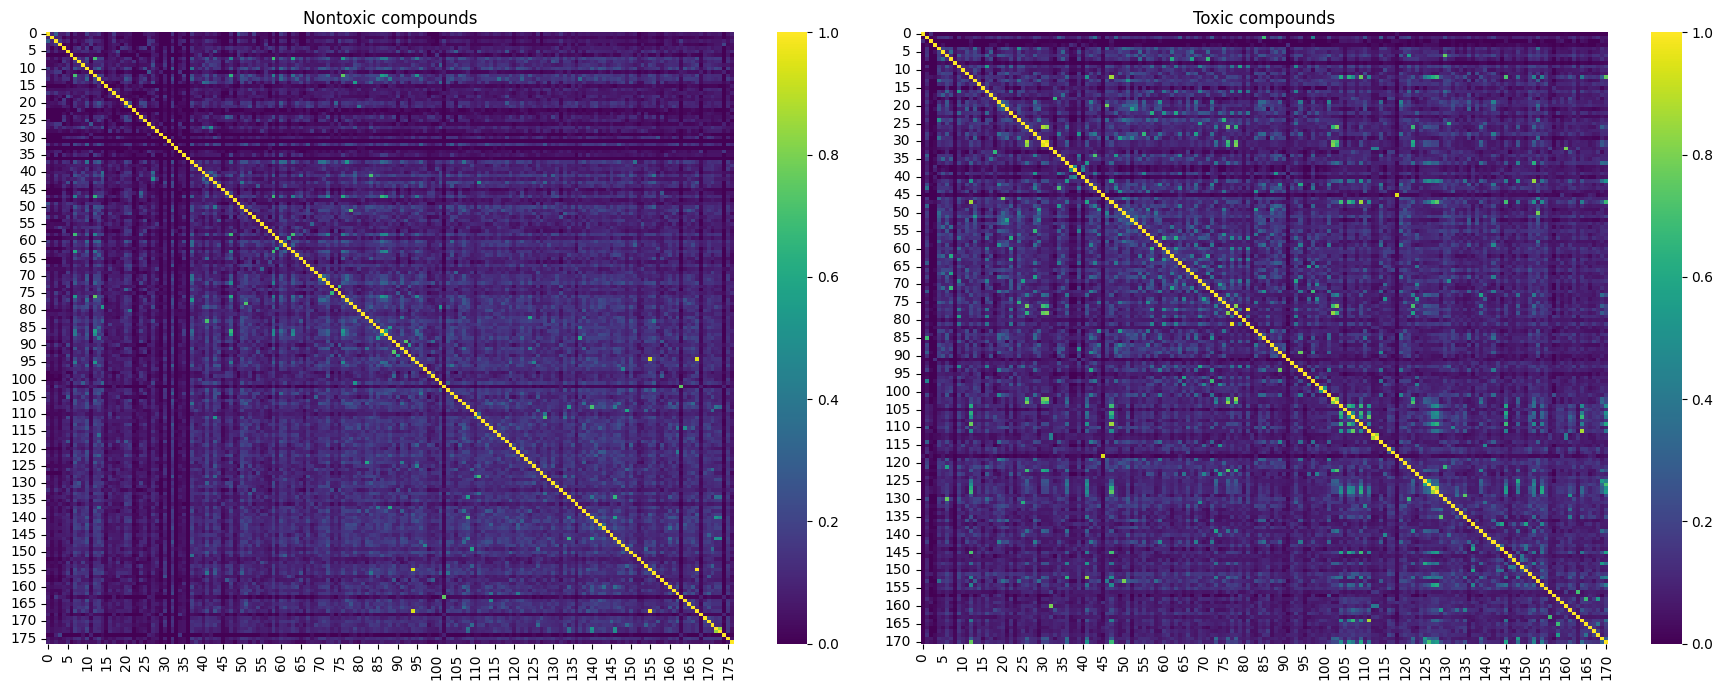

In [7]:
### Plot Similarities in Nontoxic and Toxic ###
similarity_nontox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = nontox_df['molecule'])
similarity_tox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = toxic_df['molecule'])
fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # plot matrices side-by-side

sns.heatmap(similarity_nontox, ax=axes[0], cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Nontoxic compounds")

sns.heatmap(similarity_tox, ax=axes[1], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Toxic compounds")

plt.tight_layout()
plt.show();

### Train/Test Split
The ApisTox dataset comes with three prepared train-test splits to encourage benchmarking and collaboration with the dataset. The Train/Test is split 80-20. The splits were prepared with different validation goals in mind: two are interpolative and one is extrapolative. Interpolative splits validate predictive performance inside the domain of the dataset. Extrapolative splits aim to verify out-of-domain generalization of models to structurally novel compounds. All of the details below are summarized from the 2025 ApisTox publication:
- **Stratified Random Split**

    Interpolative. Data is stratified by binary toxic and nontoxic class labels. This split may be prone to some data leakage which artificially increases test score, as this split is susceptible to clustering in chemical space (some very similar compounds make their way into both train and test sets). Scikit-learn used to prepare split.

- **Maximum Diversity Split (Max-Min Split)**

    Interpolative. The 'Maximum Diversity Picking Algorithm' is used to select test molecules so that the sum of the distances in the test set is maximized. Dice similarities with 1024 bit ECFP4 fingerprints, and the 'DeepChem' package were used to prepare this split.

- **Time Split (Chronological Split by Pubchem Date)**

    Extrapolative. The newest molecules (determined by date first appearing in bee literature, source: PubChem) are put into the test set. The assumption is that new substances are introduced over time. This is seen as an alternative to the 'scaffold split' in which new chemical 'scaffolds' (chemical moieites) are introduced over time. Pandas used to prepare split.


In [8]:
### Import All Pre-Made ApisTox Train-Test Splits ###
random_train = pd.read_csv("https://zenodo.org/records/11062077/files/random_train.csv?download=1")
random_test = pd.read_csv("https://zenodo.org/records/11062077/files/random_test.csv?download=1")
time_train = pd.read_csv("https://zenodo.org/records/11062077/files/time_train.csv?download=1")
time_test = pd.read_csv("https://zenodo.org/records/11062077/files/time_test.csv?download=1")
maxmin_train = pd.read_csv("https://zenodo.org/records/11062077/files/maxmin_train.csv?download=1")
maxmin_test = pd.read_csv("https://zenodo.org/records/11062077/files/maxmin_test.csv?download=1")

print(f"Train Set Size Verification -- Random: {random_train.shape}, Time: {time_train.shape}, MaxMin: {maxmin_train.shape} ")
print(f"Test Set Size Verification -- Random: {random_test.shape}, Time: {time_test.shape}, MaxMin: {maxmin_test.shape} ")

Train Set Size Verification -- Random: (828, 13), Time: (828, 13), MaxMin: (828, 13) 
Test Set Size Verification -- Random: (207, 13), Time: (207, 13), MaxMin: (207, 13) 


In [9]:
TARGET = "ppdb_level"
FEATURES = [col for col in df_fp.columns if col.startswith("Morgan_bit_")]

### Model Training

#### Training Dummy/Baseline Model

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, matthews_corrcoef

X = df_fp[FEATURES]
y = df_fp[TARGET]

# Split once; reuse this split for your other models
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Train dummy classifier
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

# Evaluate
y_pred_dummy = dummy.predict(X_test)

print("MCC:", matthews_corrcoef(y_test, y_pred_dummy))
print(classification_report(y_test, y_pred_dummy, zero_division=0))

DummyClassifier(strategy='most_frequent')

MCC: 0.0
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        36
           1       0.66      1.00      0.80       137
           2       0.00      0.00      0.00        34

    accuracy                           0.66       207
   macro avg       0.22      0.33      0.27       207
weighted avg       0.44      0.66      0.53       207



The dummy classifier always predicted the majority class, class 1, achieving a test accuracy of 66%. However, it failed to identify any molecules belonging to classes 0 or 2, resulting in zero recall for both classes. Its macro F1-score of 0.27 and MCC of 0 indicate poor performance across the three toxicity classes, showing that accuracy alone can be misleading for this imbalanced dataset. These results provide a baseline for evaluating whether the Random Forest and graph kernel models can better distinguish between toxicity classes

#### Training Random Forest Model
Hyperparameters are tuned using 5-fold cross-validation, model with highest Matthews Correlation Coefficient (MCC) is selected.

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef

# Hyperparameters to compare
param_grid = {
    "n_estimators": [200], #Number of decision trees in the forest. Build a forest with 200 or 500 decision trees.
    "max_depth": [None, 10, 20], # Allow no fixed depth limit, or at most 10 or 20 levels of splits along a path in each tree.
    "min_samples_leaf": [1, 2, 5], # Require at least 1, 2, or 5 training observations in every final leaf of a tree.
    "max_features": ["sqrt", 0.1, 1.0], #Consider about sqrt2048=45, 10% of 2048=204, or all 2,048 fingerprint features at each split.
    "class_weight": [None, "balanced"] #Give observations equal weight, or give minority-class observations higher weight.
}

# Preserve class proportions within each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) #shuffles observations before assigning them to folds.

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=1147),
    param_grid=param_grid,
    scoring=make_scorer(matthews_corrcoef), #Tells it to evaluate predictions using MCC.
                                                #Higher MCC is better, so it selects the combination with the highest average validation MCC across five folds.
    cv=cv,
    #n_jobs=-1,
    refit=True, #After finding the best combination, automatically trains that configuration on all of X_train and y_train.
    n_jobs=1,
    verbose=3
)

rf_search.fit(X_train, y_train)

# Best model is automatically retrained on all training data
best_rf = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print("Best mean CV MCC:", rf_search.best_score_)
print(
    "CV MCC standard deviation:",
    rf_search.cv_results_["std_test_score"][rf_search.best_index_]
)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[CV 1/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, n_estimators=200;, score=0.342 total time=   1.4s
[CV 2/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, n_estimators=200;, score=0.386 total time=   1.3s
[CV 3/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, n_estimators=200;, score=0.382 total time=   2.0s
[CV 4/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, n_estimators=200;, score=0.359 total time=   1.3s
[CV 5/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, n_estimators=200;, score=0.441 total time=   1.3s
[CV 1/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=2, n_estimators=200;, score=0.316 total time=   1.6s
[CV 2/5] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=2, n_estimators=200;, score=0.41

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=1147), n_jobs=1,
             param_grid={'class_weight': [None, 'balanced'],
                         'max_depth': [None, 10, 20],
                         'max_features': ['sqrt', 0.1, 1.0],
                         'min_samples_leaf': [1, 2, 5], 'n_estimators': [200]},
             scoring=make_scorer(matthews_corrcoef, response_method='predict'),
             verbose=3)

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Best mean CV MCC: 0.4009221196395315
CV MCC standard deviation: 0.04449207861897038


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef

# Hyperparameters to compare
param_grid = {
    "n_estimators": [200, 500], #Number of decision trees in the forest. Build a forest with 200 or 500 decision trees.
    "max_depth": [None, 10, 20], # Allow no fixed depth limit, or at most 10 or 20 levels of splits along a path in each tree.
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.1]
}

# Preserve class proportions within each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring=make_scorer(matthews_corrcoef),
    cv=cv,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X_train, y_train)

# Best model is automatically retrained on all training data
best_rf = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print("Best mean CV MCC:", rf_search.best_score_)
print(
    "CV MCC standard deviation:",
    rf_search.cv_results_["std_test_score"][rf_search.best_index_]
)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'max_features': ['sqrt', 0.1],
                         'min_samples_leaf': [1, 2, 5],
                         'n_estimators': [200, 500]},
             scoring=make_scorer(matthews_corrcoef, response_method='predict'))

Best parameters: {'max_depth': None, 'max_features': 0.1, 'min_samples_leaf': 2, 'n_estimators': 500}
Best mean CV MCC: 0.3858126056143235
CV MCC standard deviation: 0.06303665507792254


#### Train Graph Kernel Model

Hyperparameters are tuned using 5-fold cross-validation, model with highest MCC is selected.

### Model Evaluation
For all models, the following are reported:
Macro F1, AUC, MCC, precision, recall, balanced accuracy, per-class precision and recall. Confusion matrices and ROC are also generated.

### Further Data Analysis and Considerations
Addressing class imbalance: partial undersampling of majority class (apply to training portion of each cross-validation fold), class weighting.

Precision vs. Recall Tradeoff: affected by cutoff value used for logistic regression (sigmoid parameter). Will need to see if this parameter is tunable for the multiclass version. This parameter can be related to the FP/FN ratio, which can be tuned to suit use-cases/goals which differ in being more or less conservative in their predictions of compound toxicity.

| FP/FN (ratio) | plain language | drawback |
|-|-|-|
| higher | Agrochemicals that are o.k. for bees are recommended as 'do not use' | limits design space of agrochemicals|
| low | Agrochemicals which are harmful for bees are recommended as 'o.k. to use' | harms bees |